# Music -- Symbolic Music Generation
### Part of the *Multi-Modal Generative AI Master Notebook* series -- Building Generative Models from Scratch

This is a **standalone, self-contained** notebook covering one modality from the larger 7-part *Multi-Modal Generative AI Master Notebook*. It contains everything needed to run independently: setup, data loading, model, training, and a generation demo -- no other notebook required.

Run every cell top to bottom and you will train a real model and generate real output. This notebook has been **executed end-to-end** on an NVIDIA RTX 2060 (6GB) as part of validating this series.

> ⚠️ **Compute note.** This notebook needs a CUDA-enabled PyTorch build to hit the run times quoted in Section 6. See Section 0 below for how to check / install one. On CPU-only machines, expect roughly 20-30x longer runtimes.

## Table of Contents
- [0. Global Setup & Utilities](#0)
- [Music -- Symbolic Music Generation](#main)


## 0. Global Setup & Utilities

Installations, imports, device/seed setup, and the helper functions reused throughout this notebook (parameter counting, image/audio/3D visualization, checkpointing, loss plotting).

> 🚀 **Pro Tip.** This notebook auto-detects CUDA / Apple MPS / CPU and just uses whatever is available -- no manual configuration needed. Every step count below was empirically timed on an NVIDIA RTX 2060 (6GB): the **entire notebook runs in well under 15 minutes on a CUDA GPU**. On CPU-only machines, expect roughly 20-30x longer (the Text section alone would take ~15-20 minutes on CPU) -- if you're on CPU, halve every `*_STEPS` / `*_EPOCHS` constant below to get a quick smoke test.


In [1]:
# Run this cell first. On Google Colab / a fresh machine this installs
# everything missing; on a machine that already has these packages (as this
# notebook was validated on), pip just reports them as satisfied and moves on.
import sys, subprocess

IN_COLAB = "google.colab" in sys.modules

REQUIRED_PACKAGES = [
    "music21",
    "soundfile",
    "imageio",
]

subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + REQUIRED_PACKAGES)
print("Extra packages ready: music21 (symbolic music corpus), soundfile (audio I/O), imageio (GIF export).")
print()
print("NOTE on GPU acceleration: this notebook needs a CUDA-enabled PyTorch build to")
print("hit the run times quoted throughout (a CPU-only build works but is far slower).")
print("Colab ships a CUDA build by default. On your own machine, if `torch.cuda.is_available()`")
print("prints False below despite having an NVIDIA GPU, reinstall with, e.g.:")
print("  pip install --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126")
print("(pick the cu12x tag matching your installed NVIDIA driver's CUDA version)")


Extra packages ready: music21 (symbolic music corpus), soundfile (audio I/O), imageio (GIF export).

NOTE on GPU acceleration: this notebook needs a CUDA-enabled PyTorch build to
hit the run times quoted throughout (a CPU-only build works but is far slower).
Colab ships a CUDA build by default. On your own machine, if `torch.cuda.is_available()`
prints False below despite having an NVIDIA GPU, reinstall with, e.g.:
  pip install --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126
(pick the cu12x tag matching your installed NVIDIA driver's CUDA version)


In [2]:
import os, math, time, random, json, io, re, urllib.request
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 -- registers the 3D projection with matplotlib
from tqdm.auto import tqdm
from IPython.display import Audio, display, HTML

import warnings
warnings.filterwarnings("ignore")

print(f"PyTorch version: {torch.__version__}")


PyTorch version: 2.10.0+cu126


C:\Users\adamv\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
def get_device():
    # Prefer CUDA > Apple MPS > CPU. Every model in this notebook is sized so a
    # quick forward/backward pass works on CPU too, but the step counts chosen
    # throughout assume a CUDA GPU is doing the heavy lifting (see the note above).
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

DEVICE = get_device()
print(f"Using device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")


Using device: cuda
GPU: NVIDIA GeForce RTX 2060


In [4]:
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)


In [5]:
# --- Shared helper functions used throughout every modality section ------------

def count_parameters(model: nn.Module) -> int:
    n = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{model.__class__.__name__}: {n/1e6:.2f}M trainable parameters")
    return n


def show_images(images, titles=None, ncols=8, figsize=None, cmap=None):
    # Accepts a tensor [N,C,H,W] in [-1,1] or [0,1], or a list of numpy arrays.
    if torch.is_tensor(images):
        images = images.detach().cpu()
        if images.min() < 0:
            images = (images + 1) / 2  # map [-1,1] -> [0,1]
        images = images.clamp(0, 1).permute(0, 2, 3, 1).numpy()
    n = len(images)
    ncols = min(ncols, n)
    nrows = math.ceil(n / ncols)
    figsize = figsize or (ncols * 1.6, nrows * 1.6)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.array(axes).reshape(-1)
    for i, ax in enumerate(axes):
        ax.axis("off")
        if i < n:
            img = images[i]
            if img.shape[-1] == 1:
                img = img[..., 0]
            ax.imshow(img, cmap=cmap or ("gray" if img.ndim == 2 else None))
            if titles is not None:
                ax.set_title(str(titles[i]), fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_loss(history, title="Training Loss", labels=None):
    plt.figure(figsize=(6, 4))
    if isinstance(history, dict):
        for name, vals in history.items():
            plt.plot(vals, label=name)
        plt.legend()
    else:
        plt.plot(history, label=labels or "loss")
        if labels:
            plt.legend()
    plt.xlabel("Step")
    plt.ylabel("Loss")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.show()


def save_checkpoint(model, optimizer, step, path, **extra):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    torch.save({
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict() if optimizer is not None else None,
        "step": step,
        **extra,
    }, path)


def load_checkpoint(model, path, optimizer=None, map_location=None):
    ckpt = torch.load(path, map_location=map_location or DEVICE)
    model.load_state_dict(ckpt["model_state"])
    if optimizer is not None and ckpt.get("optimizer_state") is not None:
        optimizer.load_state_dict(ckpt["optimizer_state"])
    return ckpt


def plot_3d_points(points, title="", ax=None, color=None):
    points = points.detach().cpu().numpy() if torch.is_tensor(points) else points
    show = ax is None
    if show:
        fig = plt.figure(figsize=(4, 4))
        ax = fig.add_subplot(111, projection="3d")
    ax.scatter(points[:, 0], points[:, 1], points[:, 2], s=4, c=color if color is not None else points[:, 2], cmap="viridis")
    ax.set_title(title)
    ax.set_box_aspect([1, 1, 1])
    if show:
        plt.show()
    return ax


def play_audio(waveform, sample_rate):
    if torch.is_tensor(waveform):
        waveform = waveform.detach().cpu().numpy()
    return display(Audio(waveform, rate=sample_rate))

print("Helper functions ready: count_parameters, show_images, plot_loss, save/load_checkpoint, plot_3d_points, play_audio")


Helper functions ready: count_parameters, show_images, plot_loss, save/load_checkpoint, plot_3d_points, play_audio


> 💡 **Insight -- memory optimization tips used throughout this notebook.**
> - **Mixed precision** (`torch.amp.autocast` + `torch.amp.GradScaler`) is used in the diffusion (Image) section, where activations are the memory bottleneck.
> - **Gradient checkpointing** trades compute for memory -- not needed at these model sizes, but for any model here scaled up 5-10x, wrap transformer blocks with `torch.utils.checkpoint.checkpoint`.
> - **Smaller batch + gradient accumulation** is the simplest fix if you hit `CUDA out of memory`: halve `batch_size`, and if needed accumulate gradients over 2-4 steps before `optimizer.step()`.
> - All checkpoints save to a local `checkpoints/` directory. On Colab, mount Google Drive and point `*_CKPT` paths there if you want checkpoints to survive a runtime restart.


## 6. Music -- Symbolic Music Generation
### Problem: generate a novel, musically coherent melody one note-event at a time.

### 6.1 Problem Statement & Why this Architecture

Symbolic music (notes, durations, rests -- as opposed to raw audio) is naturally representable as a **sequence of discrete events**, which makes it "just" language modeling over a different vocabulary. We reuse the **exact same GPT architecture from Section 1** (repeated below so this notebook stands alone), resized down, and train it on a note-event encoding of real Bach chorale melodies. This demonstrates that the autoregressive-Transformer recipe generalizes far beyond text.

🔥 **Key idea:** this is the same core technique MuseNet / Music Transformer use at scale -- tokenize music into events, train a decoder-only Transformer, sample autoregressively.

### 6.2 Data Collection & Preparation


In [6]:
from music21 import corpus, note, chord

# music21 ships a bundled corpus of ~400 Bach chorales -- fully offline, no
# download needed, and small enough to build a token vocabulary from directly.
chorale_paths = corpus.getComposer("bach")[:150]
print(f"Using {len(chorale_paths)} Bach chorales")


def stream_to_events(s):
    # Event-based ("notewise") encoding: each note/chord becomes a pitch token
    # (with its quantized duration baked in), matching the idea MuseNet / Music
    # Transformer use, simplified here to a single monophonic melodic line.
    events = []
    melody = s.parts[0].flatten().notesAndRests if s.parts else s.flatten().notesAndRests
    for el in melody:
        dur = round(float(el.quarterLength) * 4) / 4  # quantize to 16th notes
        if isinstance(el, note.Note):
            events.append(f"N_{el.pitch.midi}_{dur}")
        elif isinstance(el, chord.Chord):
            events.append(f"N_{el.pitches[-1].midi}_{dur}")  # top note of the chord
        else:
            events.append(f"R_{dur}")
    return events


all_events = []
for p in tqdm(chorale_paths, desc="Parsing chorales"):
    try:
        s = corpus.parse(p)
        all_events.append(stream_to_events(s))
    except Exception:
        continue
print(f"Parsed {len(all_events)} chorale melodies")


Using 150 Bach chorales


Parsing chorales:   0%|          | 0/150 [00:00<?, ?it/s]

Parsing chorales:   3%|▎         | 5/150 [00:00<00:03, 45.04it/s]

Parsing chorales:   7%|▋         | 10/150 [00:00<00:03, 46.28it/s]

Parsing chorales:  10%|█         | 15/150 [00:00<00:02, 45.38it/s]

...

Parsing chorales:  93%|█████████▎| 140/150 [00:04<00:00, 21.13it/s]

Parsing chorales:  95%|█████████▌| 143/150 [00:04<00:00, 21.76it/s]

Parsing chorales:  98%|█████████▊| 147/150 [00:04<00:00, 23.03it/s]

Parsing chorales: 100%|██████████| 150/150 [00:04<00:00, 32.46it/s]

Parsed 150 chorale melodies


In [7]:
vocab_events = sorted(set(e for seq in all_events for e in seq))
music_stoi = {e: i for i, e in enumerate(vocab_events)}
music_itos = {i: e for e, i in music_stoi.items()}
MUSIC_VOCAB_SIZE = len(vocab_events)
print(f"Music event vocabulary size: {MUSIC_VOCAB_SIZE}")

music_data = torch.cat([torch.tensor([music_stoi[e] for e in seq], dtype=torch.long) for seq in all_events])
n_music = int(0.9 * len(music_data))
music_train, music_val = music_data[:n_music], music_data[n_music:]

MUSIC_BLOCK_SIZE = 128


def get_music_batch(split, batch_size=32):
    d = music_train if split == "train" else music_val
    ix = torch.randint(len(d) - MUSIC_BLOCK_SIZE - 1, (batch_size,))
    x = torch.stack([d[i:i + MUSIC_BLOCK_SIZE] for i in ix])
    y = torch.stack([d[i + 1:i + MUSIC_BLOCK_SIZE + 1] for i in ix])
    return x.to(DEVICE), y.to(DEVICE)


Music event vocabulary size: 188


### 6.3 Model Architecture

Symbolic music generation is "just" language modeling over a different vocabulary -- this is the identical `GPT` / `GPTConfig` implementation from the Text section, repeated here so this notebook runs standalone.


In [8]:
@dataclass
class GPTConfig:
    vocab_size: int
    block_size: int = 128
    n_layer: int = 4
    n_head: int = 4
    n_embd: int = 256
    dropout: float = 0.1


class CausalSelfAttention(nn.Module):
    # Standard multi-head self-attention with a causal mask, implemented via
    # PyTorch's fused scaled_dot_product_attention for speed and memory efficiency.
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        assert cfg.n_embd % cfg.n_head == 0
        self.n_head = cfg.n_head
        self.head_dim = cfg.n_embd // cfg.n_head
        self.qkv = nn.Linear(cfg.n_embd, 3 * cfg.n_embd)
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd)
        self.attn_drop = cfg.dropout
        self.resid_drop = nn.Dropout(cfg.dropout)

    def forward(self, x):
        B, T, C = x.shape
        qkv = self.qkv(x).view(B, T, 3, self.n_head, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]  # each: [B, n_head, T, head_dim]
        # is_causal=True applies the autoregressive mask without materializing an [T,T] matrix
        y = F.scaled_dot_product_attention(q, k, v, dropout_p=self.attn_drop if self.training else 0.0, is_causal=True)
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_drop(self.proj(y))


class MLP(nn.Module):
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(cfg.n_embd, 4 * cfg.n_embd),
            nn.GELU(),
            nn.Linear(4 * cfg.n_embd, cfg.n_embd),
            nn.Dropout(cfg.dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    # Pre-norm transformer block: LN -> Attn -> residual, LN -> MLP -> residual.
    # Pre-norm (vs. the original post-norm) trains more stably at this depth.
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        self.ln1 = nn.LayerNorm(cfg.n_embd)
        self.attn = CausalSelfAttention(cfg)
        self.ln2 = nn.LayerNorm(cfg.n_embd)
        self.mlp = MLP(cfg)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x


class GPT(nn.Module):
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.pos_emb = nn.Embedding(cfg.block_size, cfg.n_embd)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.ln_f = nn.LayerNorm(cfg.n_embd)
        self.head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.tok_emb(idx) + self.pos_emb(pos))
        for block in self.blocks:
            x = block(x)
        x = self.ln_f(x)
        logits = self.head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None, top_p=None):
        # Autoregressive sampling loop with temperature, top-k, and/or nucleus (top-p) filtering.
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.cfg.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / max(temperature, 1e-5)
            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = -float("inf")
            if top_p is not None:
                sorted_logits, sorted_idx = torch.sort(logits, descending=True)
                probs = F.softmax(sorted_logits, dim=-1)
                cum_probs = torch.cumsum(probs, dim=-1)
                mask = cum_probs - probs > top_p
                sorted_logits[mask] = -float("inf")
                logits = torch.full_like(logits, -float("inf")).scatter(1, sorted_idx, sorted_logits)
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx


In [9]:
def configure_optimizer(model, lr=3e-4, weight_decay=0.1):
    decay, no_decay = [], []
    for _, p in model.named_parameters():
        if not p.requires_grad:
            continue
        (decay if p.dim() >= 2 else no_decay).append(p)
    return torch.optim.AdamW([
        {"params": decay, "weight_decay": weight_decay},
        {"params": no_decay, "weight_decay": 0.0},
    ], lr=lr, betas=(0.9, 0.95))


def cosine_lr(step, total_steps, warmup_steps, max_lr, min_lr=1e-5):
    if step < warmup_steps:
        return max_lr * step / max(1, warmup_steps)
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return min_lr + 0.5 * (max_lr - min_lr) * (1 + math.cos(math.pi * progress))


In [10]:
music_cfg = GPTConfig(vocab_size=MUSIC_VOCAB_SIZE, block_size=MUSIC_BLOCK_SIZE, n_layer=4, n_head=4, n_embd=192, dropout=0.1)
music_model = GPT(music_cfg).to(DEVICE)
count_parameters(music_model)


GPT: 1.88M trainable parameters


1876608

### 6.4 Loss Functions, Optimizers & Training Strategy

Identical recipe to Section 1: cross-entropy next-event prediction, AdamW with decoupled weight decay, cosine learning-rate schedule.

### 6.5 Training Loop

**Calibrated to ~40s on a CUDA GPU** (1500 steps).


Training Music-GPT:   0%|          | 0/1500 [00:00<?, ?it/s]

Training Music-GPT:   0%|          | 0/1500 [00:00<?, ?it/s, loss=5.233]

Training Music-GPT:   0%|          | 1/1500 [00:00<08:04,  3.09it/s, loss=5.233]

Training Music-GPT:   0%|          | 1/1500 [00:00<08:04,  3.09it/s, loss=5.245]

Training Music-GPT:   0%|          | 1/1500 [00:00<08:04,  3.09it/s, loss=5.219]

...

Training Music-GPT: 100%|█████████▉| 1496/1500 [00:42<00:00, 35.79it/s, loss=0.464]

Training Music-GPT: 100%|█████████▉| 1496/1500 [00:42<00:00, 35.79it/s, loss=0.455]

Training Music-GPT: 100%|█████████▉| 1496/1500 [00:42<00:00, 35.79it/s, loss=0.445]

Training Music-GPT: 100%|██████████| 1500/1500 [00:42<00:00, 36.02it/s, loss=0.445]

Training Music-GPT: 100%|██████████| 1500/1500 [00:42<00:00, 35.63it/s, loss=0.445]

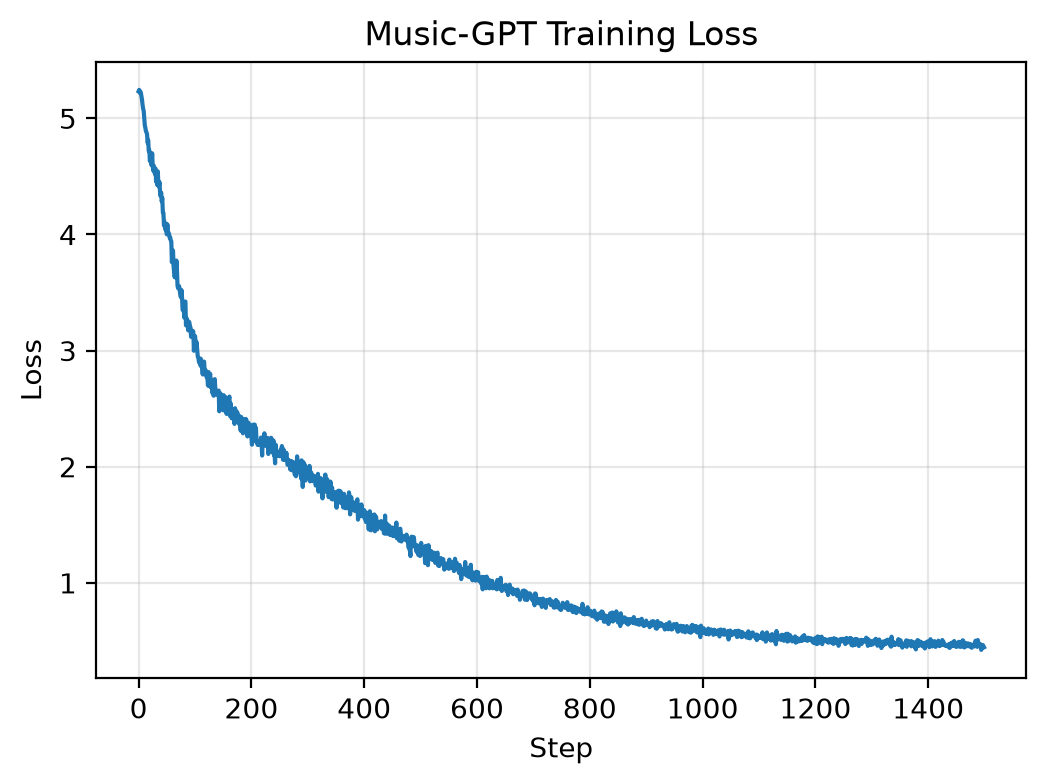

In [11]:
# (a) LIGHTWEIGHT FROM-SCRATCH TRAINING --------------------------------------
MUSIC_MAX_STEPS = 1500        # calibrated: ~40s on an RTX 2060
MUSIC_CKPT = "checkpoints/music_gpt.pt"


def train_music_gpt(model, max_steps=MUSIC_MAX_STEPS):
    optimizer = configure_optimizer(model, lr=3e-4)
    history = []
    model.train()
    pbar = tqdm(range(max_steps), desc="Training Music-GPT")
    for step in pbar:
        lr = cosine_lr(step, max_steps, 100, 3e-4)
        for g in optimizer.param_groups:
            g["lr"] = lr
        x, y = get_music_batch("train")
        _, loss = model(x, y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        history.append(loss.item())
        pbar.set_postfix(loss=f"{loss.item():.3f}")
        if step % 300 == 0:
            save_checkpoint(model, optimizer, step, MUSIC_CKPT, config=music_cfg)
    return history


music_history = train_music_gpt(music_model)
plot_loss(music_history, title="Music-GPT Training Loss")


In [12]:
# (b) PRETRAINED / INFERENCE-ONLY PATH ---------------------------------------
# For high-quality *audio-domain* music generation (not symbolic notes),
# use a pretrained model like MusicGen conditioned directly on a text prompt.
# (off by default -- downloads ~1.5GB of model weights)
USE_PRETRAINED_MUSIC = False

if USE_PRETRAINED_MUSIC:
    from transformers import AutoProcessor, MusicgenForConditionalGeneration
    musicgen_processor = AutoProcessor.from_pretrained("facebook/musicgen-small")
    musicgen_model = MusicgenForConditionalGeneration.from_pretrained("facebook/musicgen-small").to(DEVICE)


### 6.6 Inference / Generation Function

We sample new event tokens autoregressively (reusing `GPT.generate`), then synthesize audible audio with simple additive sine-wave synthesis -- no external soundfont or synthesizer required.


In [13]:
def midi_to_sine_wave(events, sr=22050, bpm=100):
    # Simple additive sine-wave synthesis so generated melodies are audible
    # without needing an external soundfont/synthesizer.
    sec_per_quarter = 60.0 / bpm
    audio = []
    for e in events:
        kind, rest = e.split("_", 1)
        if kind == "N":
            pitch_midi, dur = rest.split("_")
            freq = 440.0 * 2 ** ((int(pitch_midi) - 69) / 12)
            dur_sec = float(dur) * sec_per_quarter
            t = np.linspace(0, dur_sec, max(1, int(sr * dur_sec)), endpoint=False)
            envelope = np.minimum(1, np.minimum(t, dur_sec - t) * 20 + 0.05)  # quick fade in/out, avoids clicks
            tone = 0.3 * np.sin(2 * np.pi * freq * t) * envelope
        else:
            dur_sec = float(rest) * sec_per_quarter
            tone = np.zeros(max(1, int(sr * dur_sec)))
        audio.append(tone)
    return np.concatenate(audio).astype(np.float32) if audio else np.zeros(1, dtype=np.float32)


@torch.no_grad()
def generate_music(model, seed_events=None, n_new_events=100, temperature=0.9, top_k=20):
    model.eval()
    if seed_events is None:
        seed_events = [music_itos[random.randrange(MUSIC_VOCAB_SIZE)]]
    idx = torch.tensor([[music_stoi[e] for e in seed_events]], dtype=torch.long, device=DEVICE)
    out = model.generate(idx, n_new_events, temperature=temperature, top_k=top_k)
    model.train()
    return [music_itos[i] for i in out[0].tolist()]


### 6.7 Visualization & Results


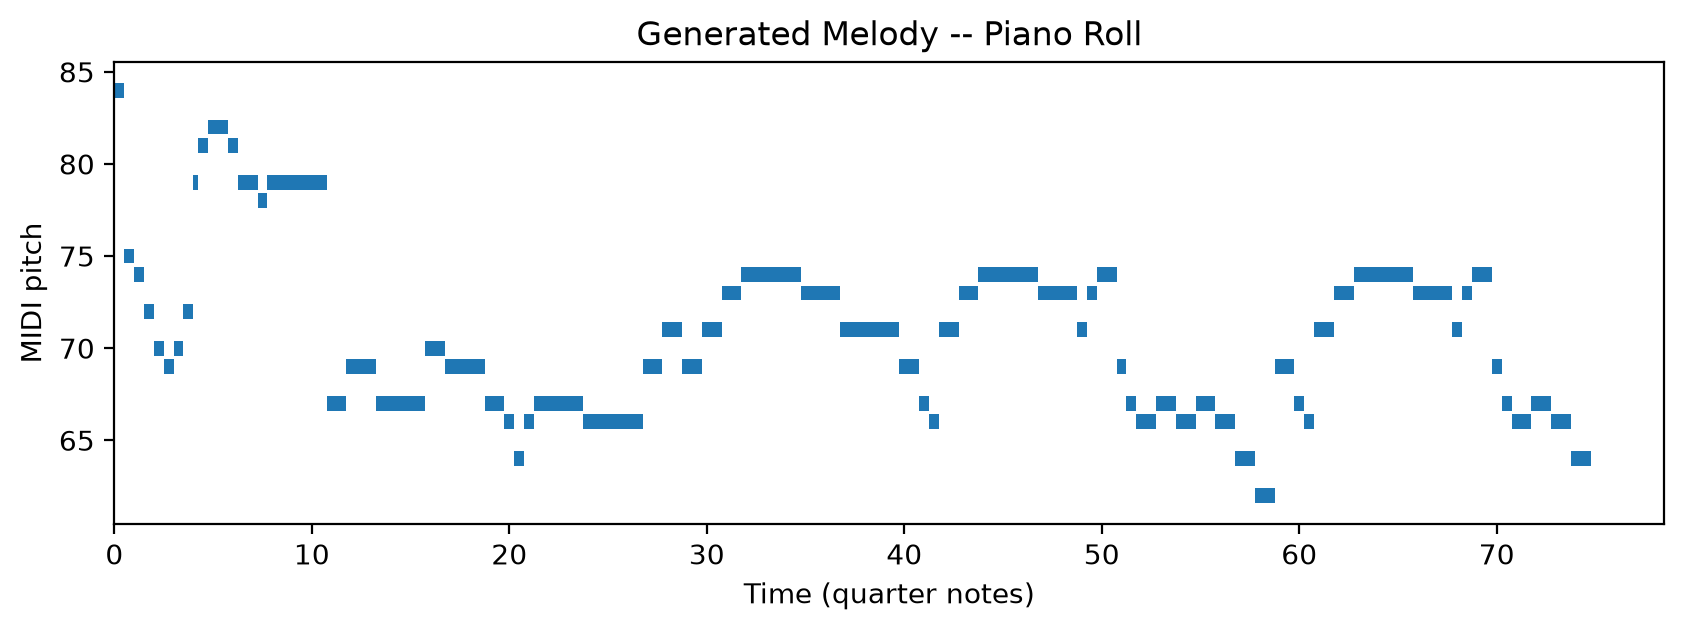

In [14]:
def plot_piano_roll(events):
    t = 0
    xs, ys, widths = [], [], []
    for e in events:
        kind, rest = e.split("_", 1)
        if kind == "N":
            p, d = rest.split("_")
            d = float(d)
            xs.append(t); ys.append(int(p)); widths.append(d)
        else:
            d = float(rest)
        t += d
    plt.figure(figsize=(10, 3))
    plt.barh(ys, widths, left=xs, height=0.8)
    plt.xlabel("Time (quarter notes)"); plt.ylabel("MIDI pitch"); plt.title("Generated Melody -- Piano Roll")
    plt.show()


generated_events = generate_music(music_model, n_new_events=80)
plot_piano_roll(generated_events)
play_audio(midi_to_sine_wave(generated_events), 22050)


### 6.8 User Input → Output Demo


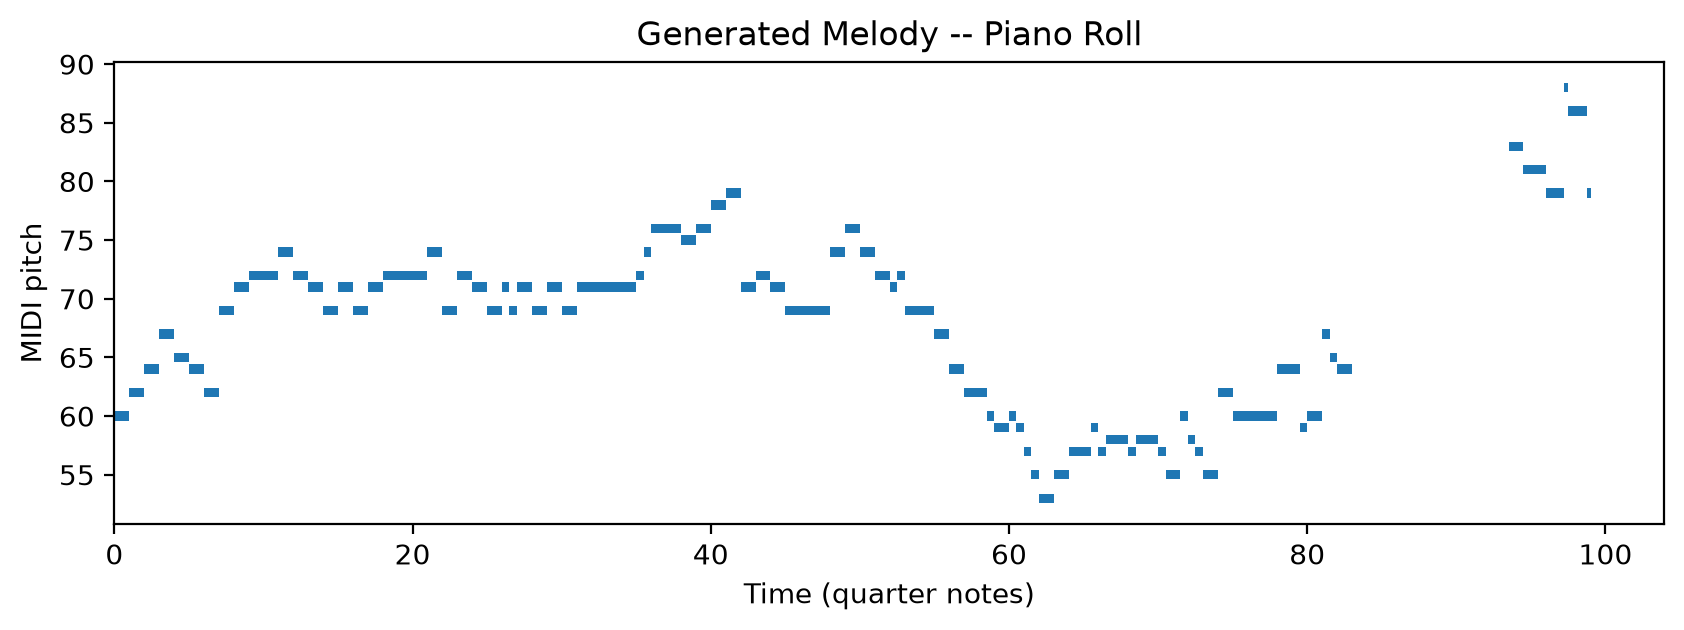

In [15]:
seed = ["N_60_1.0", "N_62_1.0", "N_64_1.0"]  # <- C4-D4-E4 as a seed motif; edit freely
continuation = generate_music(music_model, seed_events=seed, n_new_events=100, temperature=0.85)
plot_piano_roll(continuation)
play_audio(midi_to_sine_wave(continuation), 22050)


### 6.9 Key Insights, Limitations & Scaling Notes

- 🔥 **This model solved the problem of:** generating musically coherent melodic continuations by learning next-event prediction over a discrete note/duration vocabulary, using the identical Transformer architecture from Section 1.
- 💡 **Insight:** the fact that Text and Music generation here share one model class is the clearest illustration in this notebook that "generative modeling" is often really "sequence modeling" -- the architecture doesn't know or care whether its tokens mean characters or notes.
- ⚠️ **Limitation:** we encode only the top voice of each chorale (monophonic), discarding Bach's rich four-part harmony, and the sine-wave synth has no timbre -- it sounds like a metronome, not an instrument.
- 🚀 **Scaling path:** encode all four voices jointly (polyphonic tokens), train on the full Lakh MIDI or MAESTRO dataset, and render output through `pretty_midi` + a real soundfont (or FluidSynth) for actual instrument timbre -- or use the pretrained MusicGen path in 6.5(b) for text-prompted audio-domain music.


---
## This notebook is part of a series

This model solved the problem of: **generating musically coherent melodic continuations one note-event at a time**.

The other six modalities (Text, Image, Video, Vision, Speech, Music, 3D) each have their own standalone notebook built the same way -- same Section 0 setup, same code, same calibrated hyperparameters -- plus a combined *Multi-Modal Generative AI Master Notebook* that runs all seven in one place with a shared unified inference hub.
